In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")

In [2]:
BLUE, RED = "steelblue", "tomato"
sns.set_style("whitegrid")

In [3]:
d = pd.read_csv("Fraud_cleaned.csv")
print(d.shape)

(30000, 11)


In [4]:
print("Missing values:", d.isnull().sum().sum(), "| Duplicate rows:", d.duplicated().sum())
d.head()

Missing values: 0 | Duplicate rows: 0


,Step,Type,Amount,Name Orig,Oldbalanceorg,NewbalanceOrig,NameDest,Oldbalancedest,Newbalancedest,IsFraud,IsFlaggedFraud
0,522,TRANSFER,3635328.11,C743822679,10436.00,0.0,C1534408959,273252.13,3908580.24,0,0
1,42,CASH_OUT,5032484.73,C253446049,5032484.73,0.0,C57938337,873589.17,5906073.90,1,0
2,396,CASH_OUT,334672.99,C808555938,20408.00,0.0,C105578345,205414.96,540087.95,0,0
3,182,PAYMENT,18838.31,C262764700,10492.00,0.0,M2082487144,0.00,0.00,0,0
4,402,PAYMENT,4991.69,C1021808615,0.00,0.0,M1127549690,0.00,0.00,0,0


##### data quality checks

#### fix negative amounts (the minus sign is the error), then create helper columns used in the graphs

In [5]:
d["Amount"] = d["Amount"].abs()

d["hour"]       = d["Step"] % 24                                   # hour of the day (Step = hours)
d["night"]      = d["hour"].between(0, 8).astype(int)              # 1 = hour 0 to 8
d["orig_empty"] = (d["NewbalanceOrig"] == 0).astype(int)           # sender empty after transaction
d["drain_all"]  = (((d["Amount"] - d["Oldbalanceorg"]).abs() < 1) & (d["Oldbalanceorg"] > 0)).astype(int)
                                                                   # amount = whole sender balance
d["diff_orig"]  = d["Oldbalanceorg"] - d["NewbalanceOrig"]
d["diff_dest"]  = d["Newbalancedest"] - d["Oldbalancedest"]
d["error_orig"] = d["Oldbalanceorg"] - d["Amount"] - d["NewbalanceOrig"]
d["error_dest"] = d["Oldbalancedest"] + d["Amount"] - d["Newbalancedest"]
d["log_Amount"] = np.log1p(d["Amount"])

#### Graph 1: Class balance (Normal vs Fraud)

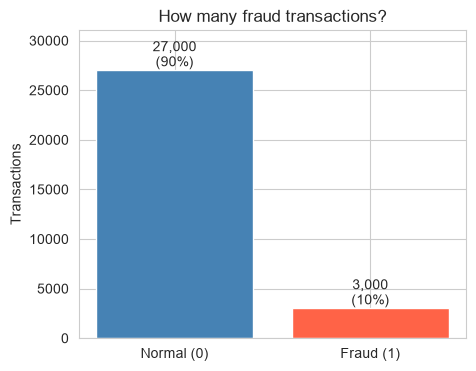

In [6]:
counts = d["IsFraud"].value_counts().sort_index()
plt.figure(figsize=(5, 4))
bars = plt.bar(["Normal (0)", "Fraud (1)"], counts.values, color=[BLUE, RED])
for b, v in zip(bars, counts.values):
    plt.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/len(d)*100:.0f}%)", ha="center", va="bottom")
plt.title("How many fraud transactions?"); plt.ylabel("Transactions"); plt.ylim(0, counts.max()*1.15)
plt.show()

#### Graph 2: Fraud by transaction Type

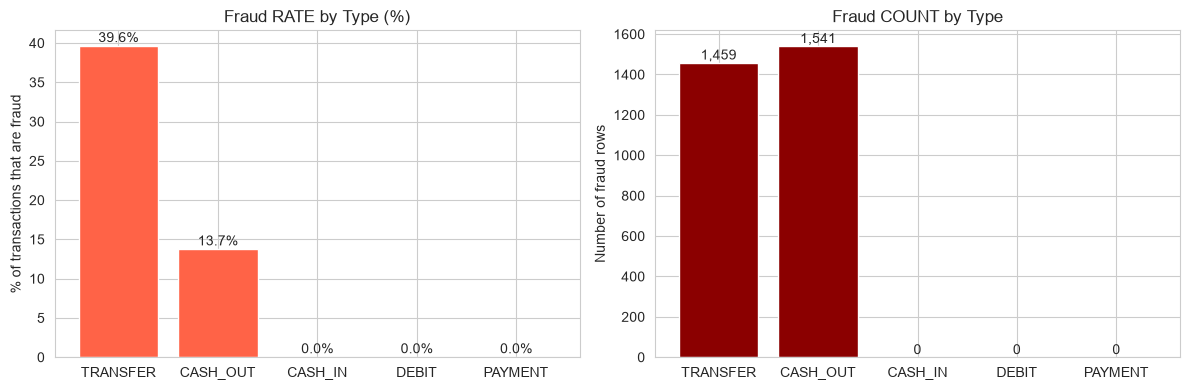

In [7]:
rate = (d.groupby("Type")["IsFraud"].mean() * 100).sort_values(ascending=False)
cnt  = d[d.IsFraud == 1]["Type"].value_counts().reindex(rate.index).fillna(0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(rate.index, rate.values, color=RED)
for i, v in enumerate(rate.values): ax[0].text(i, v + 0.5, f"{v:.1f}%", ha="center")
ax[0].set_title("Fraud RATE by Type (%)"); ax[0].set_ylabel("% of transactions that are fraud")
ax[1].bar(cnt.index, cnt.values, color="darkred")
for i, v in enumerate(cnt.values): ax[1].text(i, v + 15, f"{int(v):,}", ha="center")
ax[1].set_title("Fraud COUNT by Type"); ax[1].set_ylabel("Number of fraud rows")
plt.tight_layout(); plt.show()

#### Graph 3: Fraud rate by hour of the day

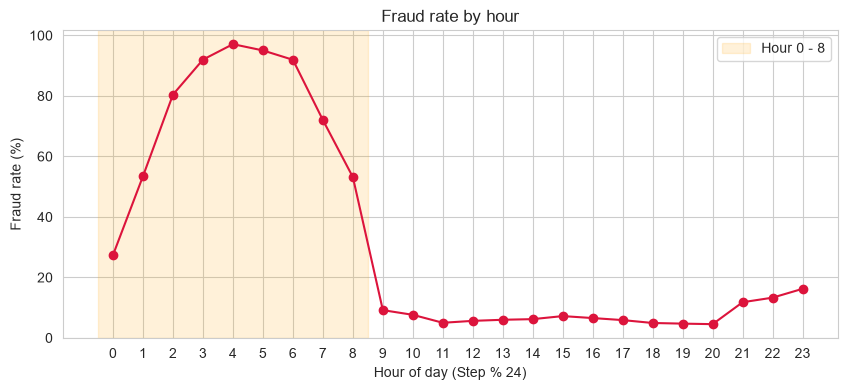

In [8]:
hourly = d.groupby("hour")["IsFraud"].mean() * 100
plt.figure(figsize=(10, 4))
plt.plot(hourly.index, hourly.values, marker="o", color="crimson")
plt.axvspan(-0.5, 8.5, color="orange", alpha=0.15, label="Hour 0 - 8")
plt.xticks(range(24)); plt.xlabel("Hour of day (Step % 24)"); plt.ylabel("Fraud rate (%)")
plt.title("Fraud rate by hour"); plt.legend(); plt.show()

#### Graph 4: Transaction Amount - fraud vs normal

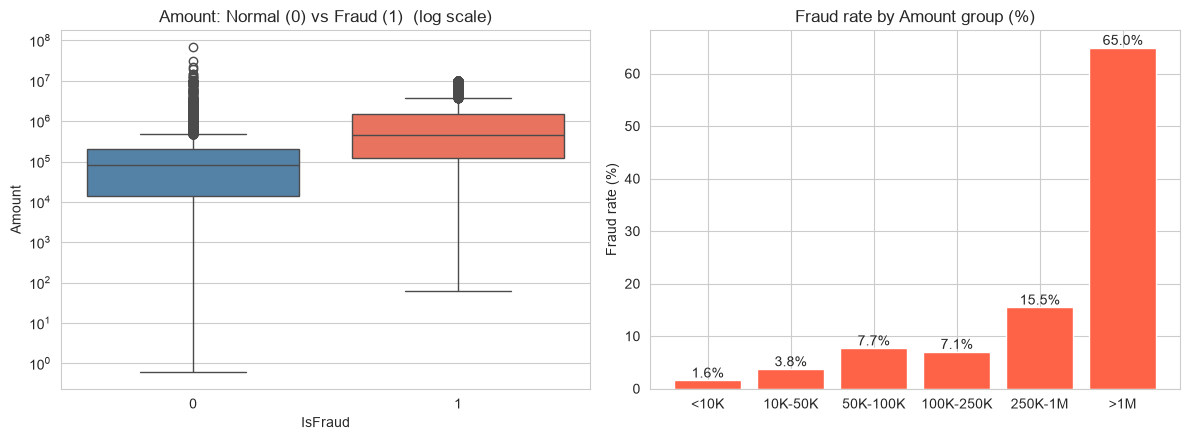

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x="IsFraud", y="Amount", data=d[d.Amount > 0], hue="IsFraud",
            palette=[BLUE, RED], legend=False, ax=ax[0])
ax[0].set_yscale("log"); ax[0].set_title("Amount: Normal (0) vs Fraud (1)  (log scale)")

bins = [0, 10_000, 50_000, 100_000, 250_000, 1_000_000, np.inf]
labels = ["<10K", "10K-50K", "50K-100K", "100K-250K", "250K-1M", ">1M"]
amt_rate = d.groupby(pd.cut(d["Amount"], bins, labels=labels), observed=True)["IsFraud"].mean() * 100
ax[1].bar(amt_rate.index.astype(str), amt_rate.values, color=RED)
for i, v in enumerate(amt_rate.values): ax[1].text(i, v + 0.5, f"{v:.1f}%", ha="center")
ax[1].set_title("Fraud rate by Amount group (%)"); ax[1].set_ylabel("Fraud rate (%)")
plt.tight_layout(); plt.show()

#### Graph 5: Correlation

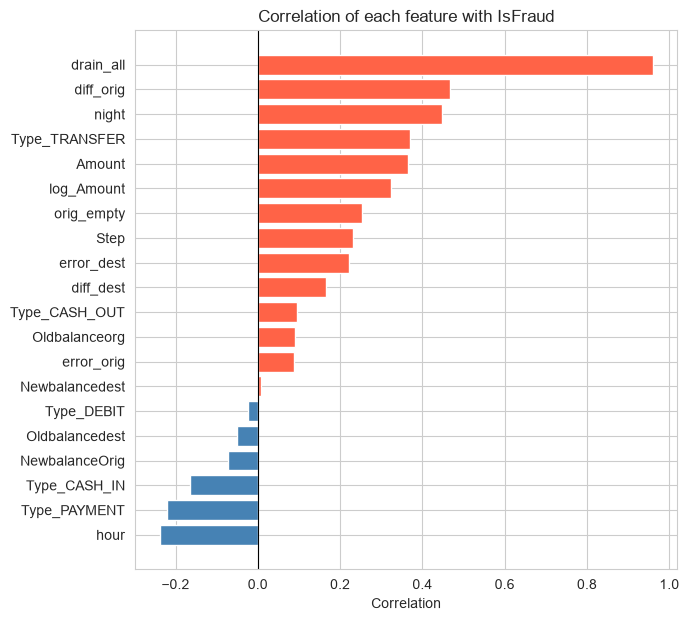

In [10]:
X = pd.concat([d[["Step", "hour", "night", "Amount", "log_Amount", "Oldbalanceorg", "NewbalanceOrig",
                  "Oldbalancedest", "Newbalancedest", "diff_orig", "diff_dest",
                  "error_orig", "error_dest", "orig_empty", "drain_all"]],
               pd.get_dummies(d["Type"], prefix="Type", dtype=int)], axis=1)

corr_fraud = X.corrwith(d["IsFraud"]).sort_values()
plt.figure(figsize=(7, 7))
plt.barh(corr_fraud.index, corr_fraud.values, color=np.where(corr_fraud.values > 0, RED, BLUE))
plt.axvline(0, color="k", lw=0.8)
plt.title("Correlation of each feature with IsFraud"); plt.xlabel("Correlation"); plt.show()

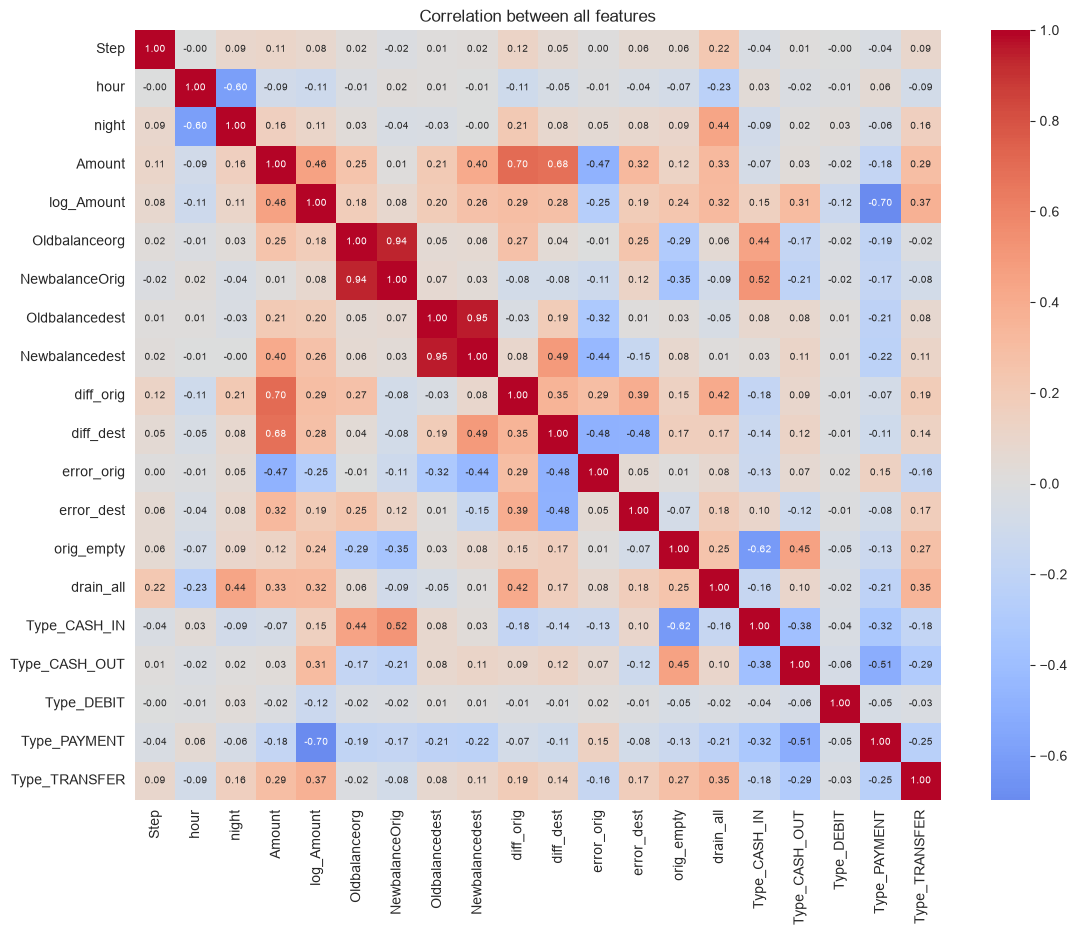

In [11]:
plt.figure(figsize=(13, 10))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation between all features"); plt.show()

In [12]:
d.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Step            30000 non-null  int64  
 1   Type            30000 non-null  str    
 2   Amount          30000 non-null  float64
 3   Name Orig       30000 non-null  str    
 4   Oldbalanceorg   30000 non-null  float64
 5   NewbalanceOrig  30000 non-null  float64
 6   NameDest        30000 non-null  str    
 7   Oldbalancedest  30000 non-null  float64
 8   Newbalancedest  30000 non-null  float64
 9   IsFraud         30000 non-null  int64  
 10  IsFlaggedFraud  30000 non-null  int64  
 11  hour            30000 non-null  int64  
 12  night           30000 non-null  int64  
 13  orig_empty      30000 non-null  int64  
 14  drain_all       30000 non-null  int64  
 15  diff_orig       30000 non-null  float64
 16  diff_dest       30000 non-null  float64
 17  error_orig      30000 non-null  float64
 1

In [13]:
d.to_csv("Fraud_cleaned_extra.csv",index=False)